# Gradient Boosting for Tabular Classification

This project started as a class comparison of XGBoost, LightGBM and CatBoost. The revised experiment asks how they compare with simple baselines, where they make mistakes, and how much the obesity results depend on height and weight.

This notebook walks through the saved, verified run. Training lives in `src/benchmark.py`, so the notebook and command-line experiment use the same implementation. Run `python src/benchmark.py` from the repository root to regenerate the results before reopening this walkthrough.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "benchmark.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "benchmark.py").exists(), "Open the notebook from the repository or notebooks folder."
REPORTS = ROOT / "reports"
sys.path.insert(0, str(ROOT / "src"))
from benchmark import load_data, preprocessing

def figure(name):
    display(Image(filename=str(REPORTS / "figures" / f"{name}.png")))

## 1. Check the data

The obesity file contains mixed numeric and categorical inputs and seven classes. The cancer file contains 30 numeric inputs and two classes. The benchmark removes IDs from predictors, drops entirely empty columns, and removes exact duplicate records before splitting.

The obesity dataset is 77% synthetic according to UCI. This matters: random splits can contain related synthetic examples, even after exact duplicates are removed. The data files do not supply the lineage needed to group those examples. Sources and licenses are in `data/README.md`.

In [2]:
scenarios, audit = load_data()
display(audit)
for name, (X, y, labels) in scenarios.items():
    print(f"{name}: {X.shape[0]} rows, {X.shape[1]} features, {len(labels)} classes")
display(scenarios["obesity_full"][0].head())

obesity_full: 2087 rows, 16 features, 7 classes
obesity_without_body_size: 2087 rows, 14 features, 7 classes
breast_cancer: 569 rows, 30 features, 2 classes


,dataset,raw_rows,rows,exact_duplicates_removed,features,missing_values
0,obesity,2111,2087,24,16,0
1,breast_cancer,569,569,0,30,0


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


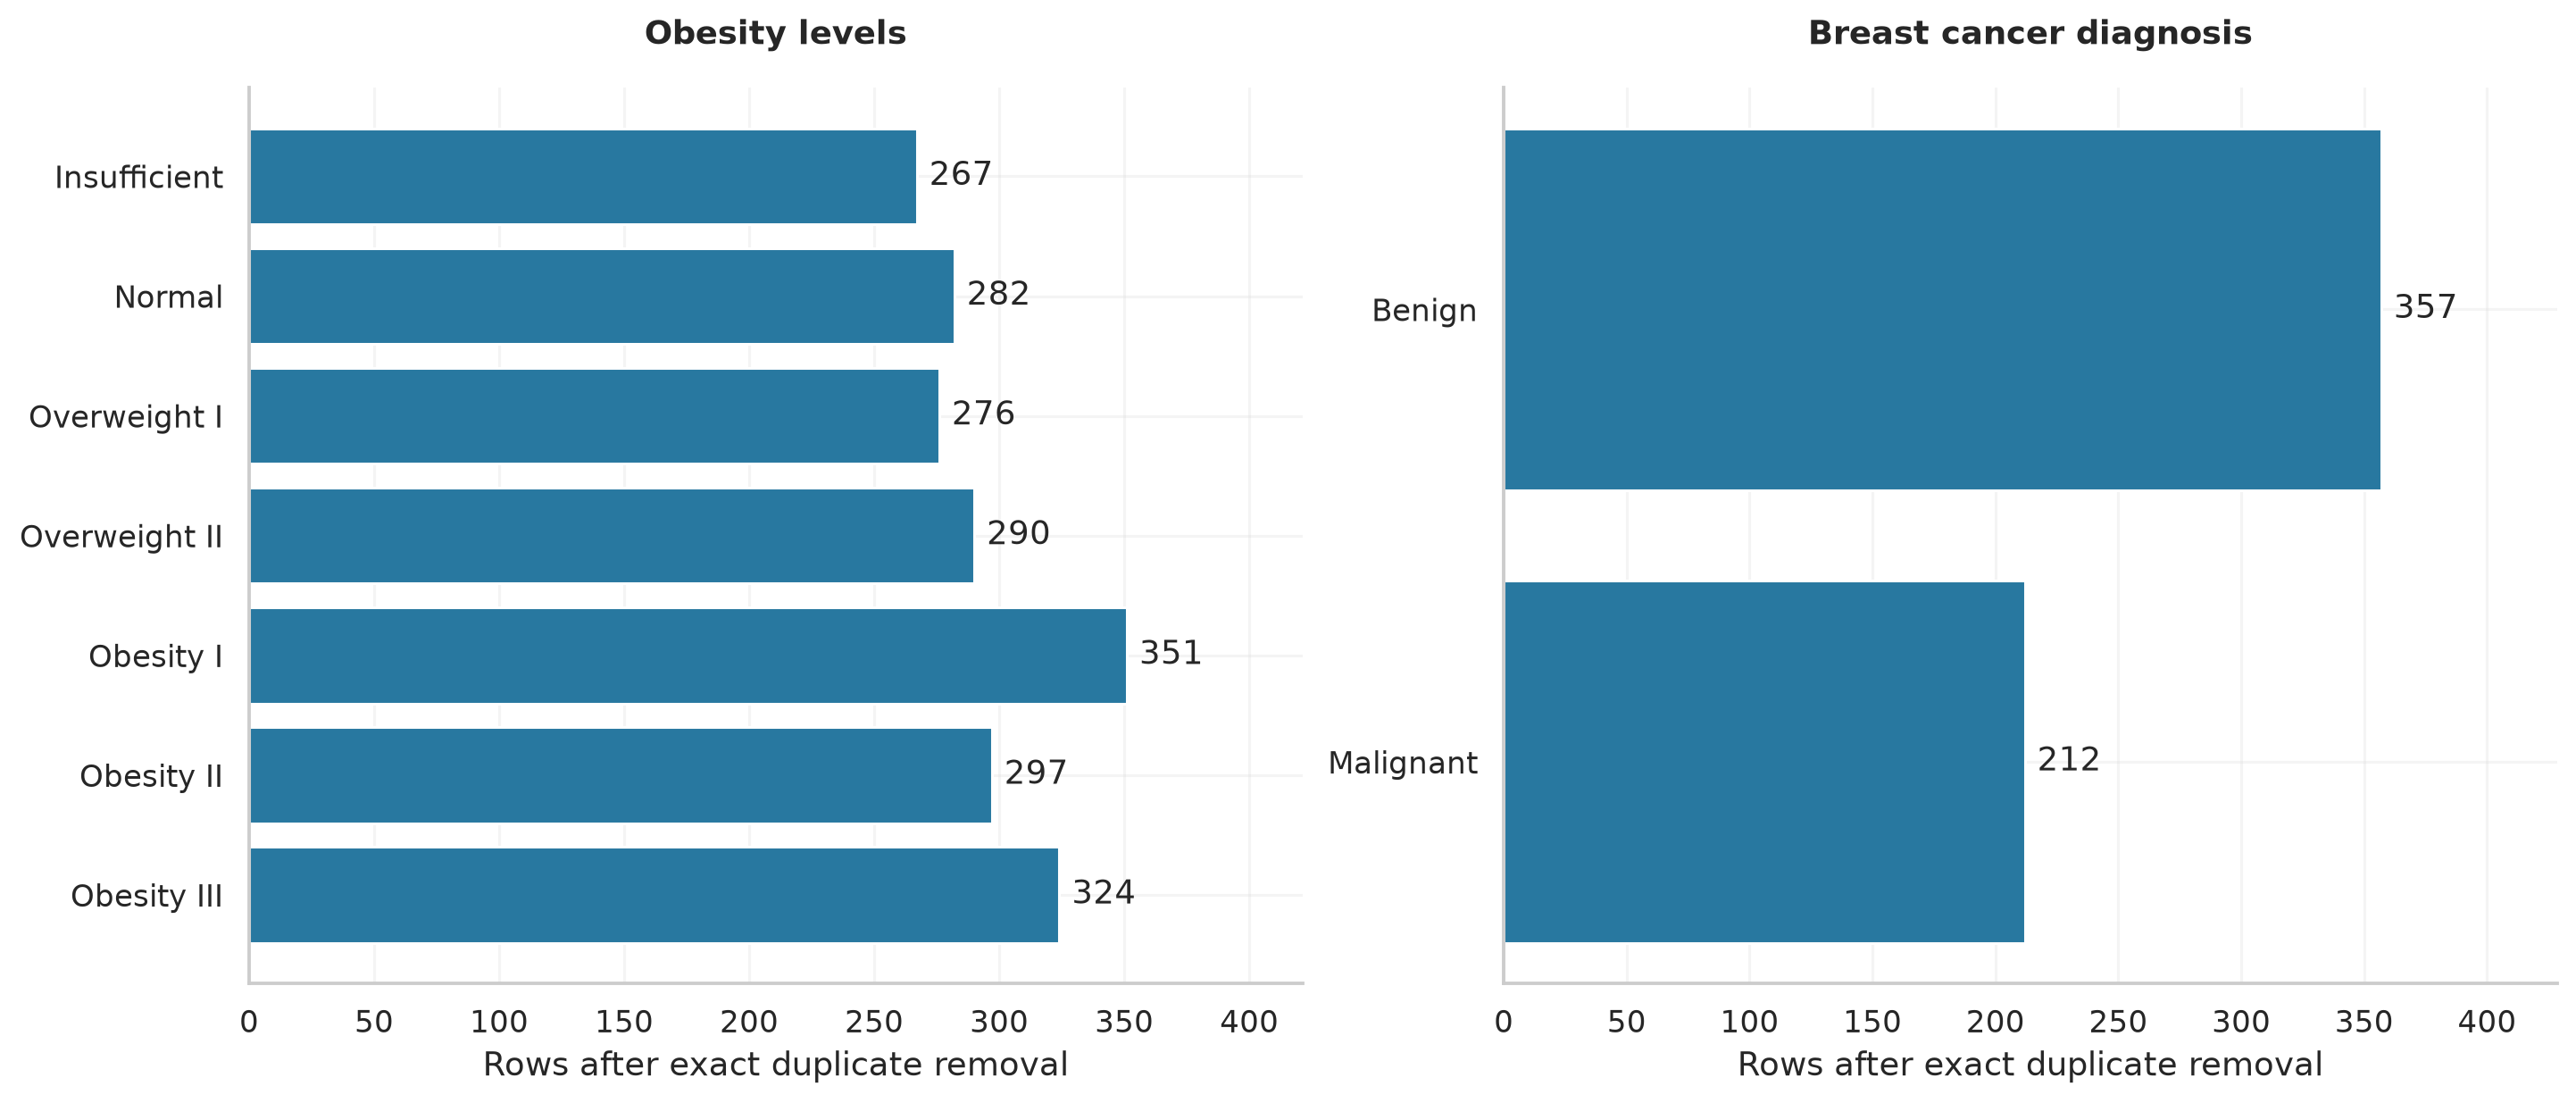

In [3]:
figure("class_distribution")

## 2. Separate selection from evaluation

The revised pipeline reserves a stratified 20% test split first. Five-fold stratified cross-validation runs on the remaining 80%. All candidates use the same folds. The two obesity scenarios also share exactly the same row assignments.

Imputation, numeric scaling and categorical encoding are fitted inside each fold. The winner is selected using development mean **macro-F1**, which gives each class equal weight. Test results are inspected only after selection. The original class notebook already evaluated these data, so this is a retrospective benchmark rather than a fresh independent validation.

The candidates are a majority-class predictor, logistic regression, XGBoost, LightGBM and CatBoost. All boosting candidates use 500 iterations, a learning rate of 0.05 and depth 6. These shared settings are a controlled comparison, not a thorough search for each library's best configuration.

In [4]:
metadata = json.loads((REPORTS / "run_metadata.json").read_text())
display(pd.Series({k: metadata[k] for k in ["seed", "folds", "test_fraction", "iterations", "threads", "selection_metric", "python", "platform"]}))
# This is the fold-fitted preprocessing object used by the experiment.
preprocessing(scenarios["obesity_full"][0])

Out[4]: 
ColumnTransformer(sparse_threshold=0,
                  transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['Age', 'Height', 'Weight', 'FCVC', 'NCP',
                                  'CH2O', 'FAF', 'TUE']),
                                ('categorical',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Gender', 'family_history_with_overweight',
                                  

seed                                          42
folds                                          5
test_fraction                                0.2
iterations                                   500
threads                                        4
selection_metric    development CV mean macro-F1
python                                   3.12.14
platform            macOS-15.3.1-arm64-arm-64bit
dtype: object

## 3. Compare development scores

Error bars show standard deviation across the five validation folds. They describe fold variability; they are not 95% confidence intervals. Small differences between candidates should not be read as proof that one library is better.

Macro-F1  ... Fit time (s)
Scenario                            Model                         ...             
Obesity · all inputs                Majority baseline      4.12%  ...        0.005
                                    Logistic regression   86.66%  ...        0.023
                                    XGBoost               95.83%  ...        1.339
                                    LightGBM              96.87%  ...        2.226
                                    CatBoost              95.99%  ...        1.973
Obesity · without height and weight Majority baseline      4.12%  ...        0.005
                                    Logistic regression   56.90%  ...        0.029
                                    XGBoost               82.92%  ...        1.747
                                    LightGBM              82.80%  ...        3.162
                                    CatBoost              83.20%  ...        1.884
Breast cancer                       Majority baseline     38.51%  ...        0.002
                                    Logistic regression   97.16%  ...        0.003
                                    XGBoost               96.94%  ...        0.149
                                    LightGBM              96.92%  ...        0.212
                                    CatBoost              97.16%  ...        0.519

[15 rows x 4 columns]

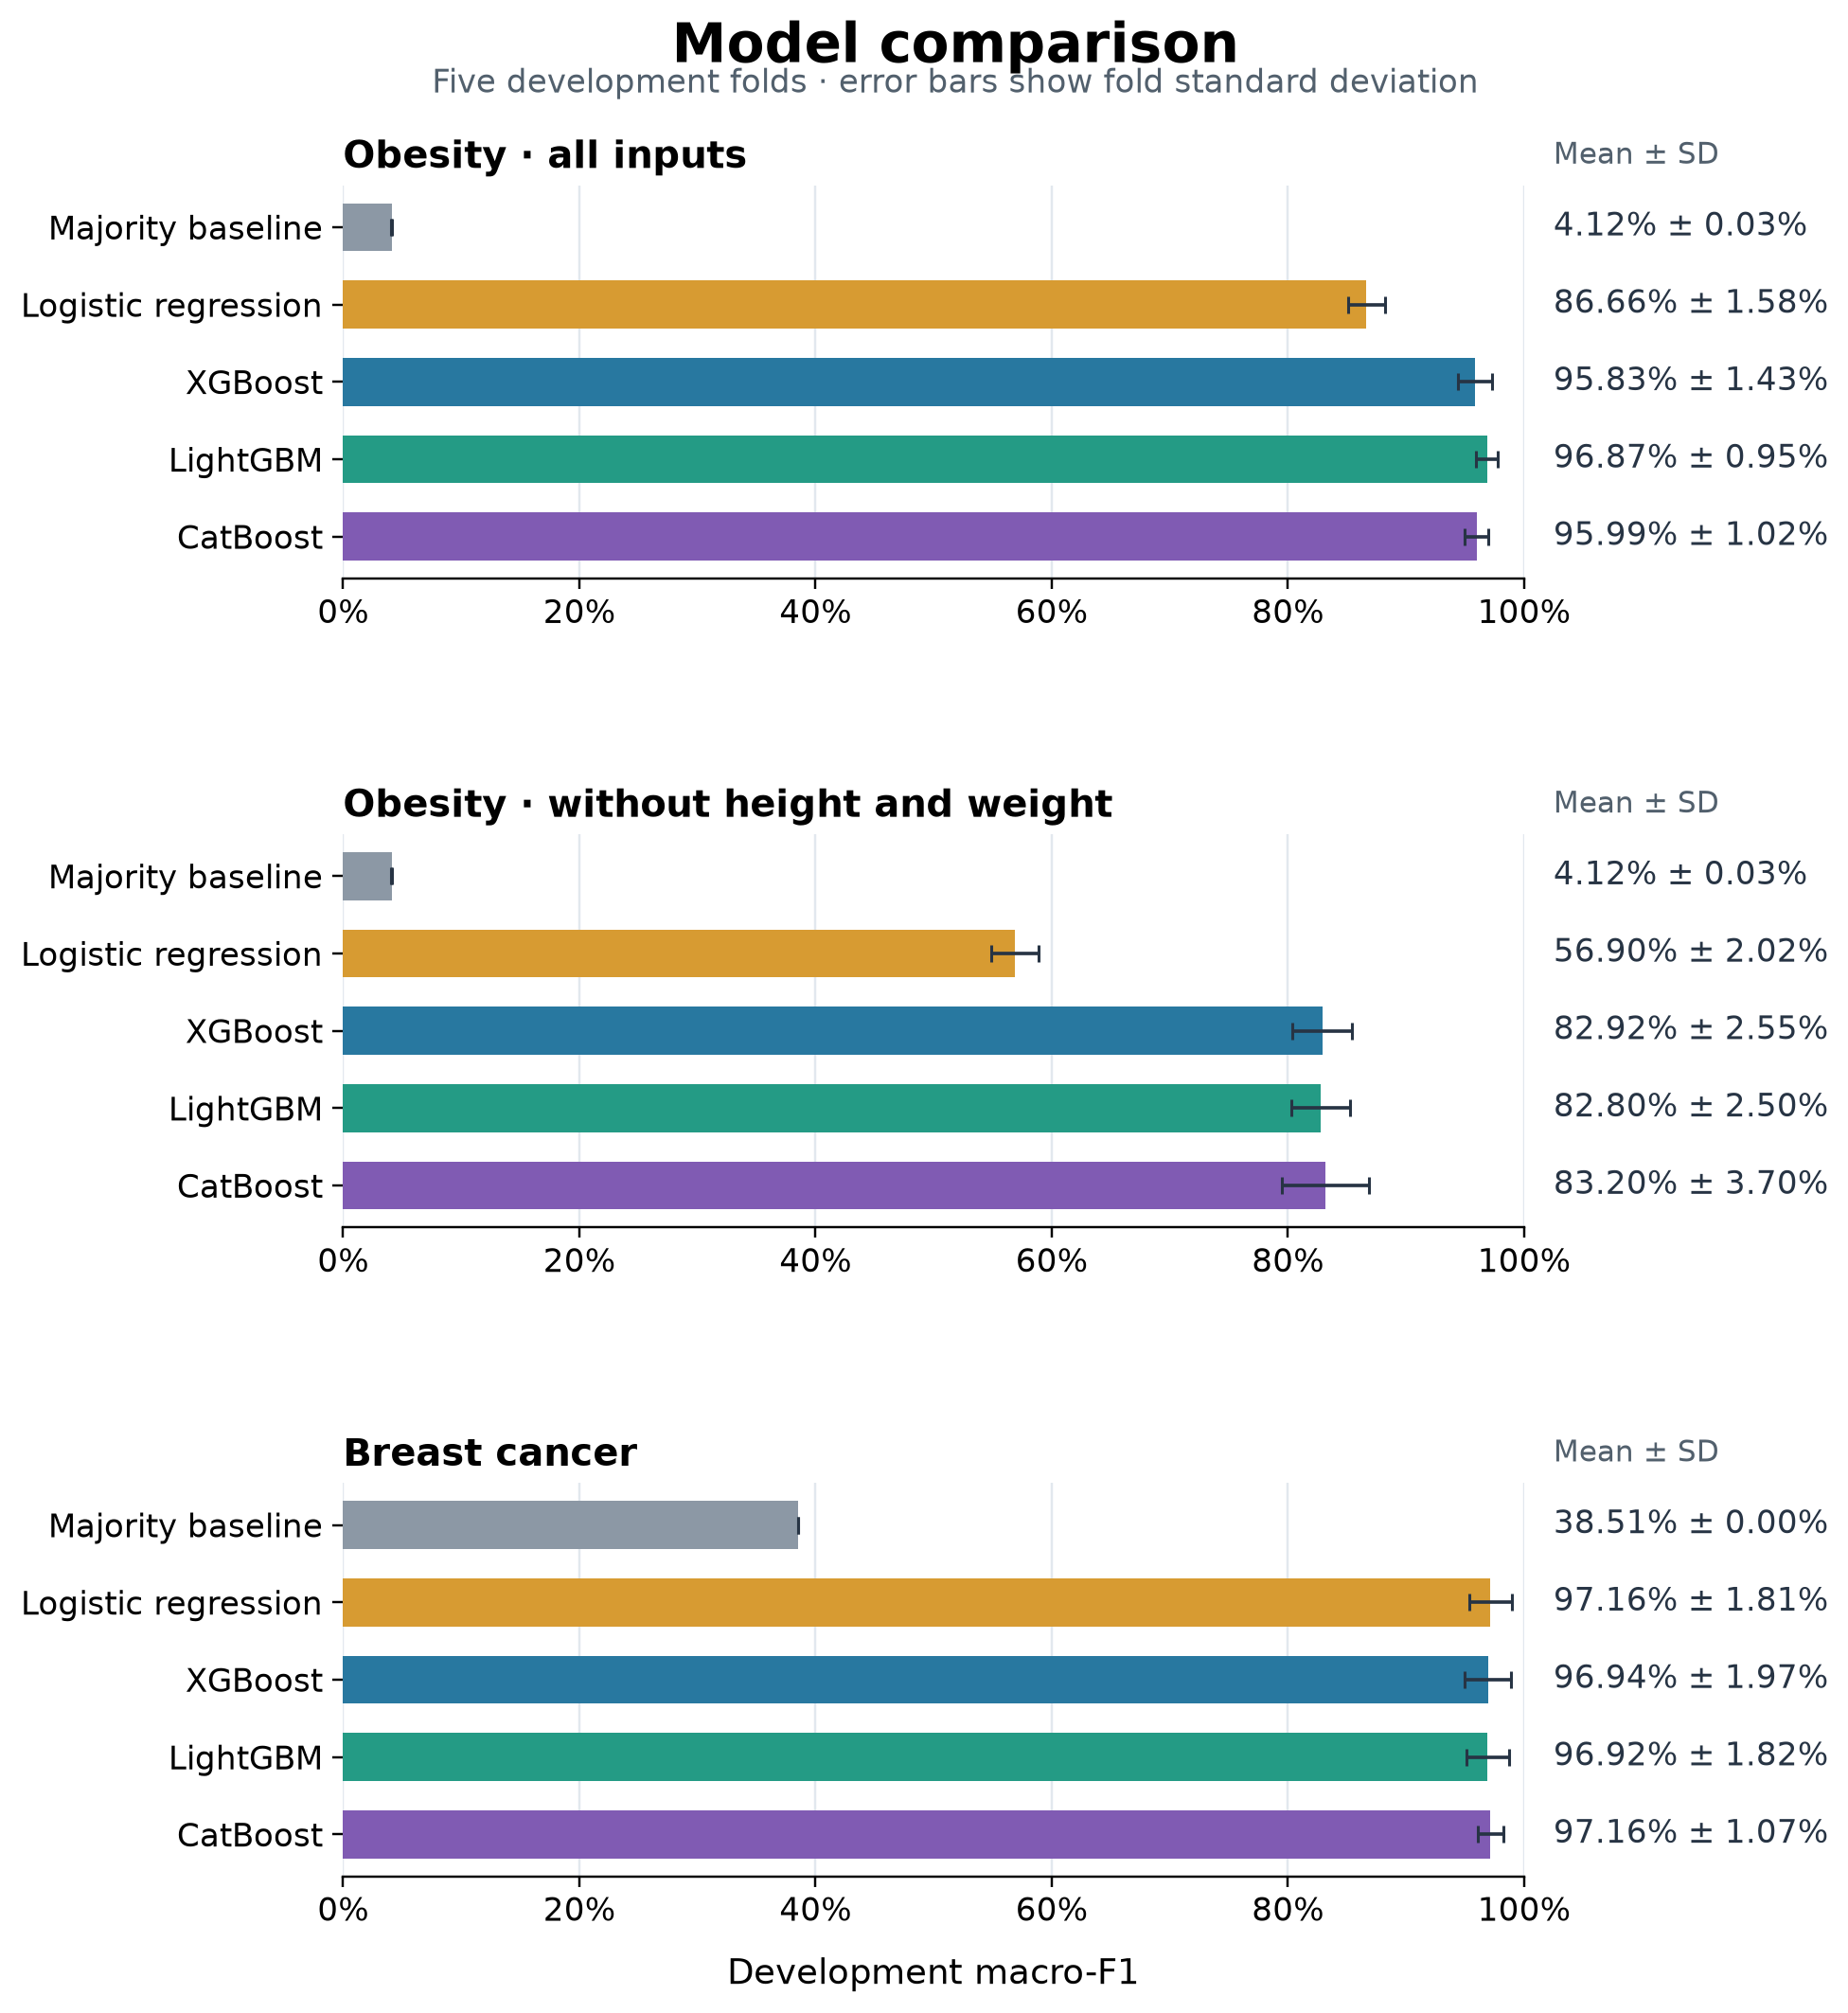

In [5]:
from benchmark import plot_comparison

cv = pd.read_csv(REPORTS / "cv_summary.csv")
scenario_order = ["obesity_full", "obesity_without_body_size", "breast_cancer"]
scenario_names = {
    "obesity_full": "Obesity · all inputs",
    "obesity_without_body_size": "Obesity · without height and weight",
    "breast_cancer": "Breast cancer",
}
view = cv[["scenario", "model", "macro_f1_mean", "macro_f1_std", "accuracy_mean", "fit_seconds_mean"]].copy()
view["scenario"] = view["scenario"].map(scenario_names)
view = view.rename(columns={
    "scenario": "Scenario", "model": "Model", "macro_f1_mean": "Macro-F1",
    "macro_f1_std": "Fold SD", "accuracy_mean": "Accuracy", "fit_seconds_mean": "Fit time (s)",
})
for column in ["Macro-F1", "Fold SD", "Accuracy"]:
    view[column] = view[column].map(lambda value: f"{value:.2%}")
view["Fit time (s)"] = view["Fit time (s)"].map(lambda value: f"{value:.3f}")
display(view.set_index(["Scenario", "Model"]))

# Regenerate the image from the current CSV rather than displaying an old export.
plot_comparison(cv, scenario_order)
figure("model_comparison")

## 4. Look beyond the main obesity score

The second obesity scenario removes height and weight, while retaining the same cleaned rows, split and validation folds. It asks what performance remains when body-size measurements are unavailable.

A drop in performance indicates dependence on the input scenario. It does not prove that lifestyle features cause weight categories, or turn the reduced model into a validated future-risk predictor.

In [6]:
boosting = cv[cv.model.isin(["XGBoost", "LightGBM", "CatBoost"])]
ablation = boosting.pivot(index="model", columns="scenario", values="macro_f1_mean")
ablation = ablation[["obesity_full", "obesity_without_body_size"]]
ablation["drop_percentage_points"] = 100 * (ablation.obesity_full - ablation.obesity_without_body_size)
display(ablation.round(4))

scenario,obesity_full,obesity_without_body_size,drop_percentage_points
model,,,
CatBoost,0.9599,0.8320,12.7834
LightGBM,0.9687,0.8280,14.0617
XGBoost,0.9583,0.8292,12.9127


## 5. Assess the selected models on the held-out split

Only the selected candidate in each scenario is evaluated here. Test accuracy and macro-F1 include stratified bootstrap percentile intervals from 1,000 resamples of the saved predictions. These intervals condition on the fitted model and this split; they do not include retraining or model-selection uncertainty.

,scenario,model,development_rows,test_rows,accuracy,macro_f1,weighted_f1,accuracy_ci_low,accuracy_ci_high,macro_f1_ci_low,macro_f1_ci_high,malignant_recall,roc_auc
0,obesity_full,LightGBM,1669,418,0.9665,0.9664,0.9664,0.9498,0.9833,0.9498,0.9831,NaN,NaN
1,obesity_without_body_size,CatBoost,1669,418,0.8589,0.8556,0.8589,0.8254,0.8923,0.8228,0.8890,NaN,NaN
2,breast_cancer,Logistic regression,455,114,0.9649,0.9619,0.9647,0.9298,0.9912,0.9221,0.9906,0.9286,0.996


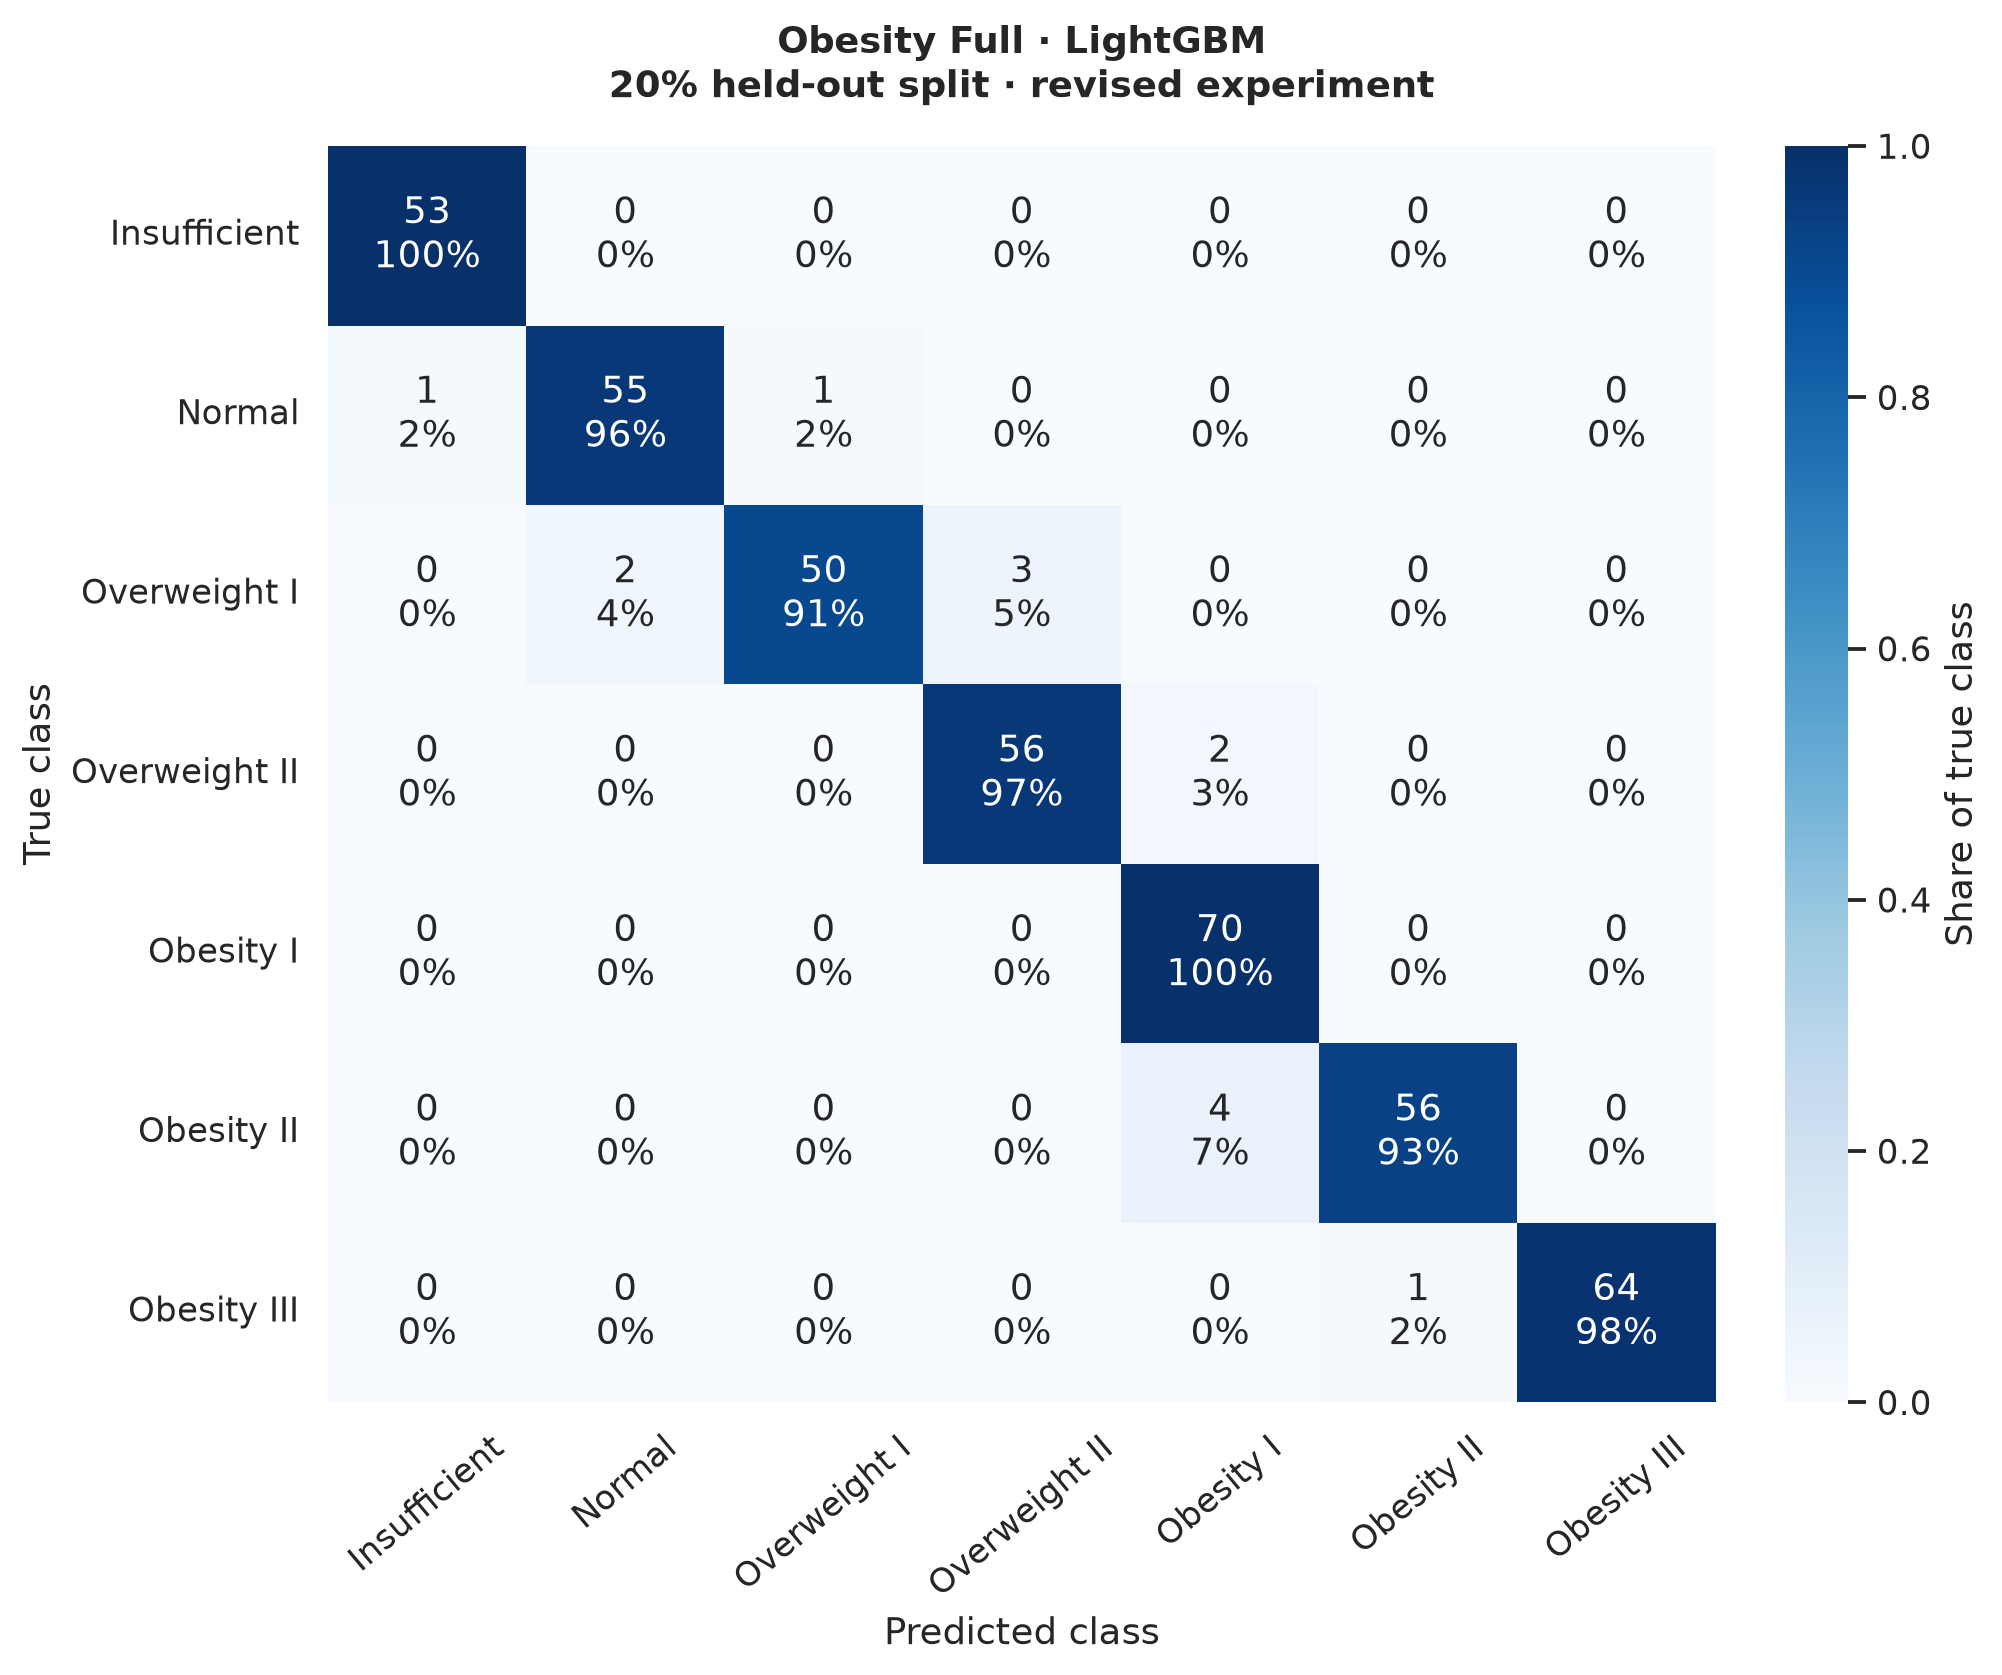

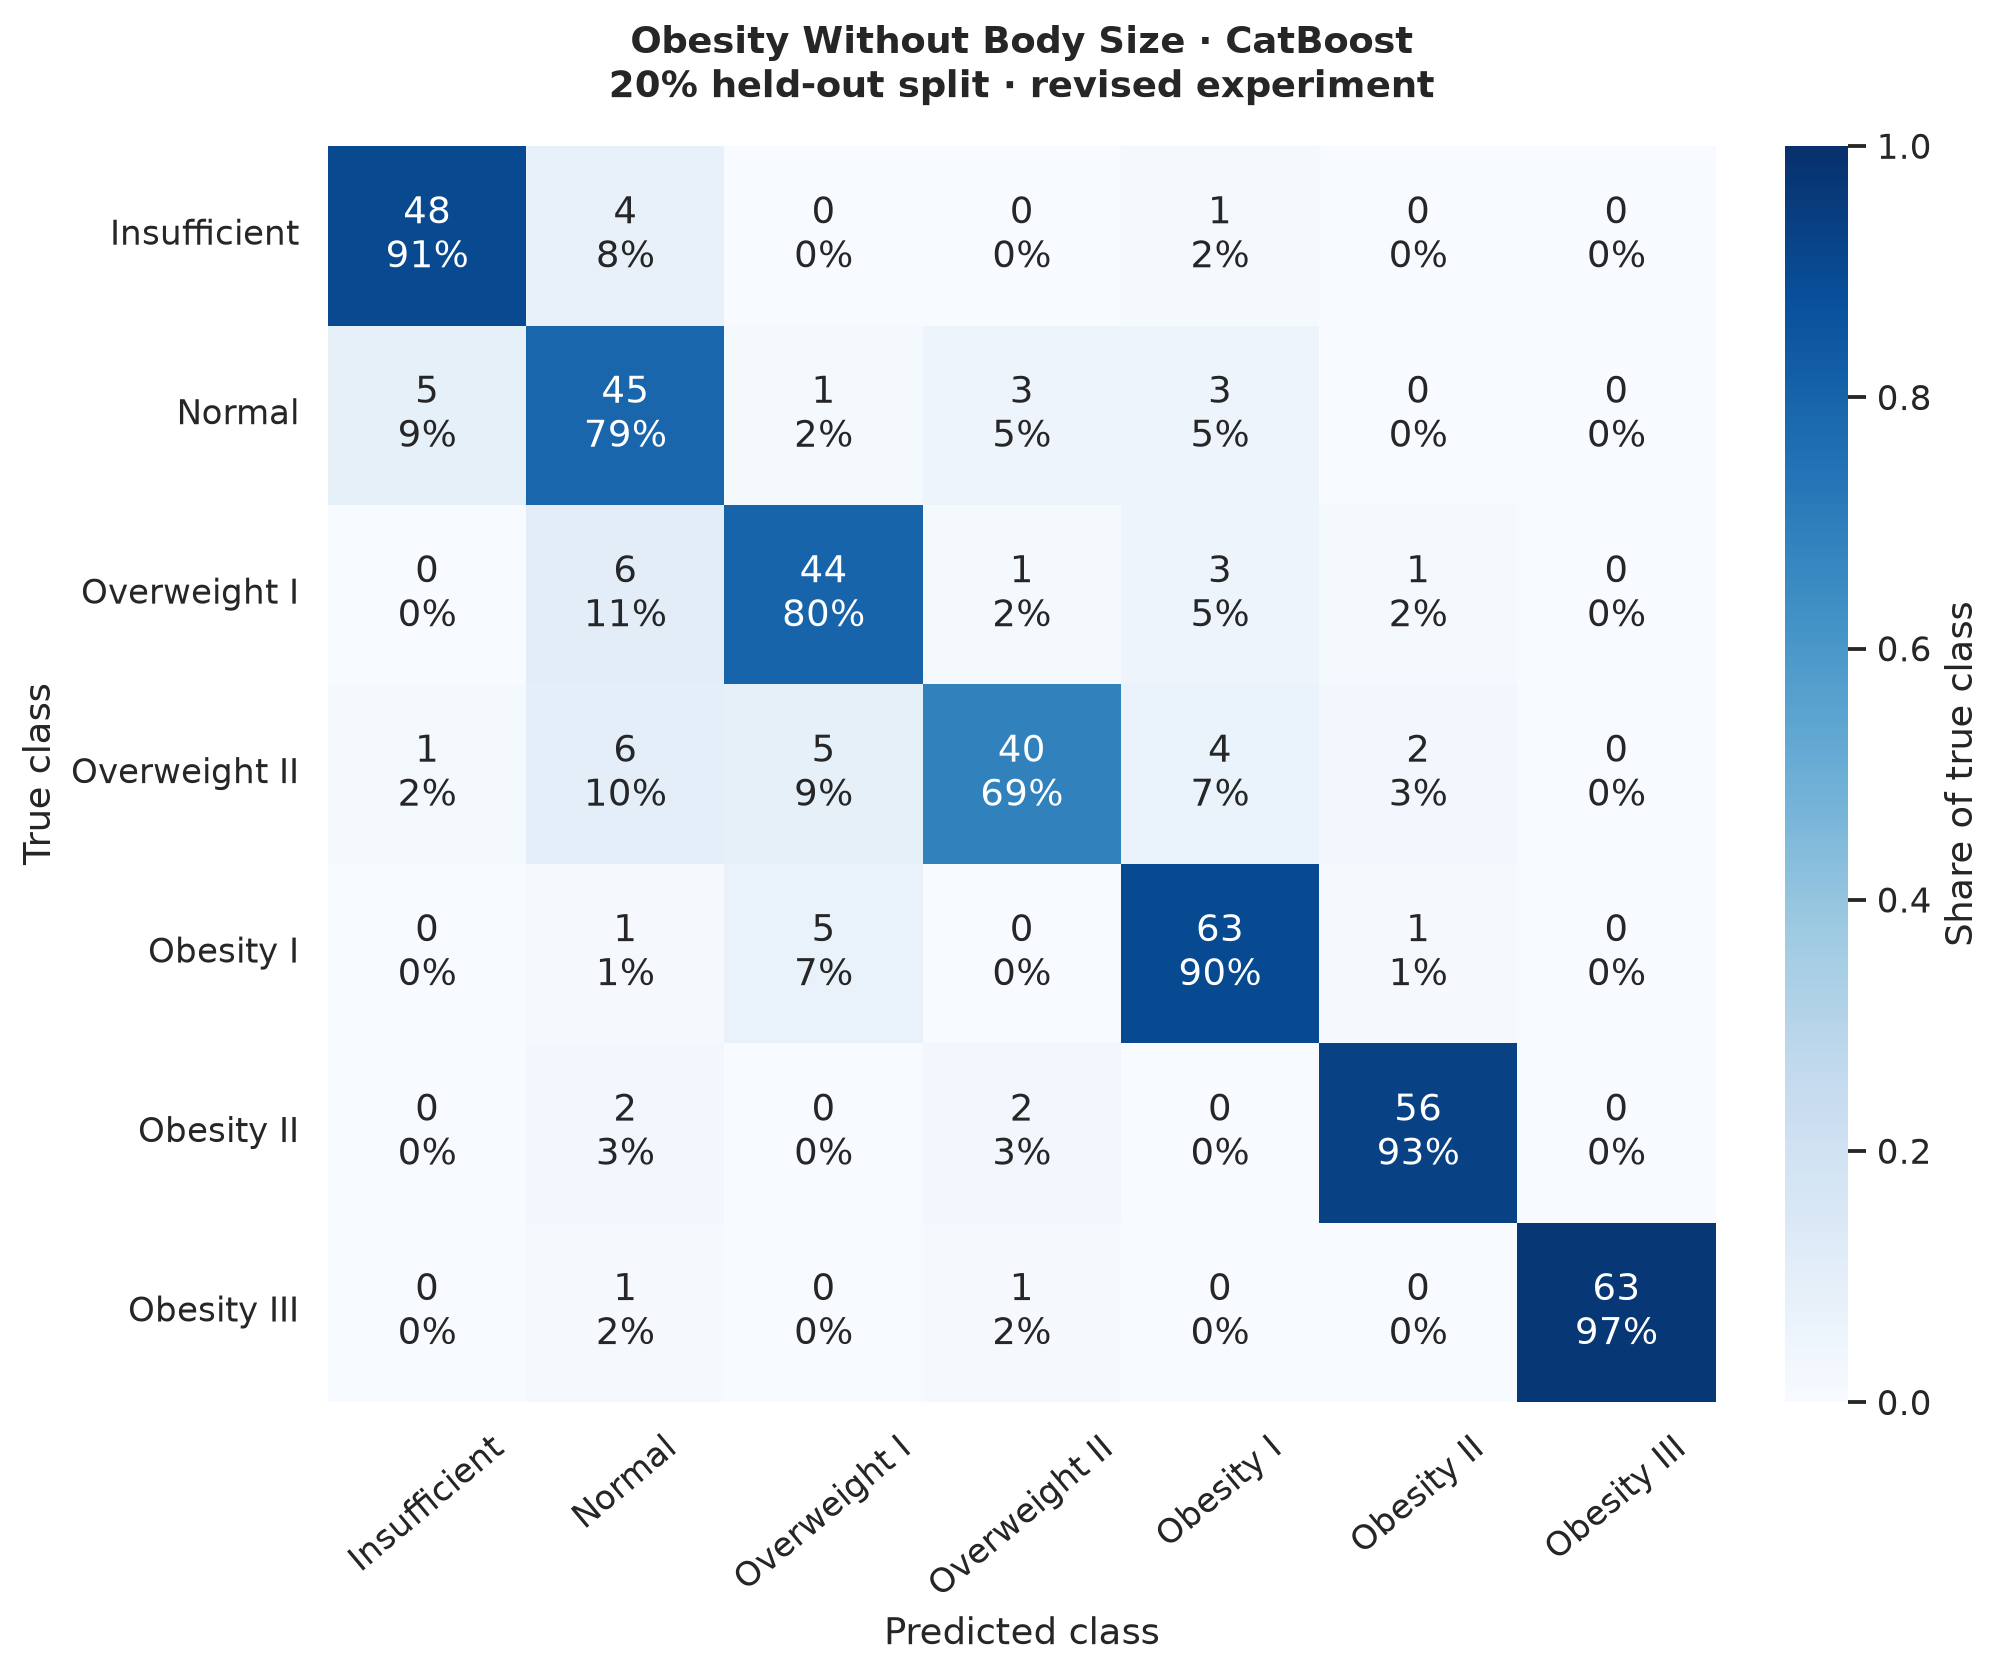

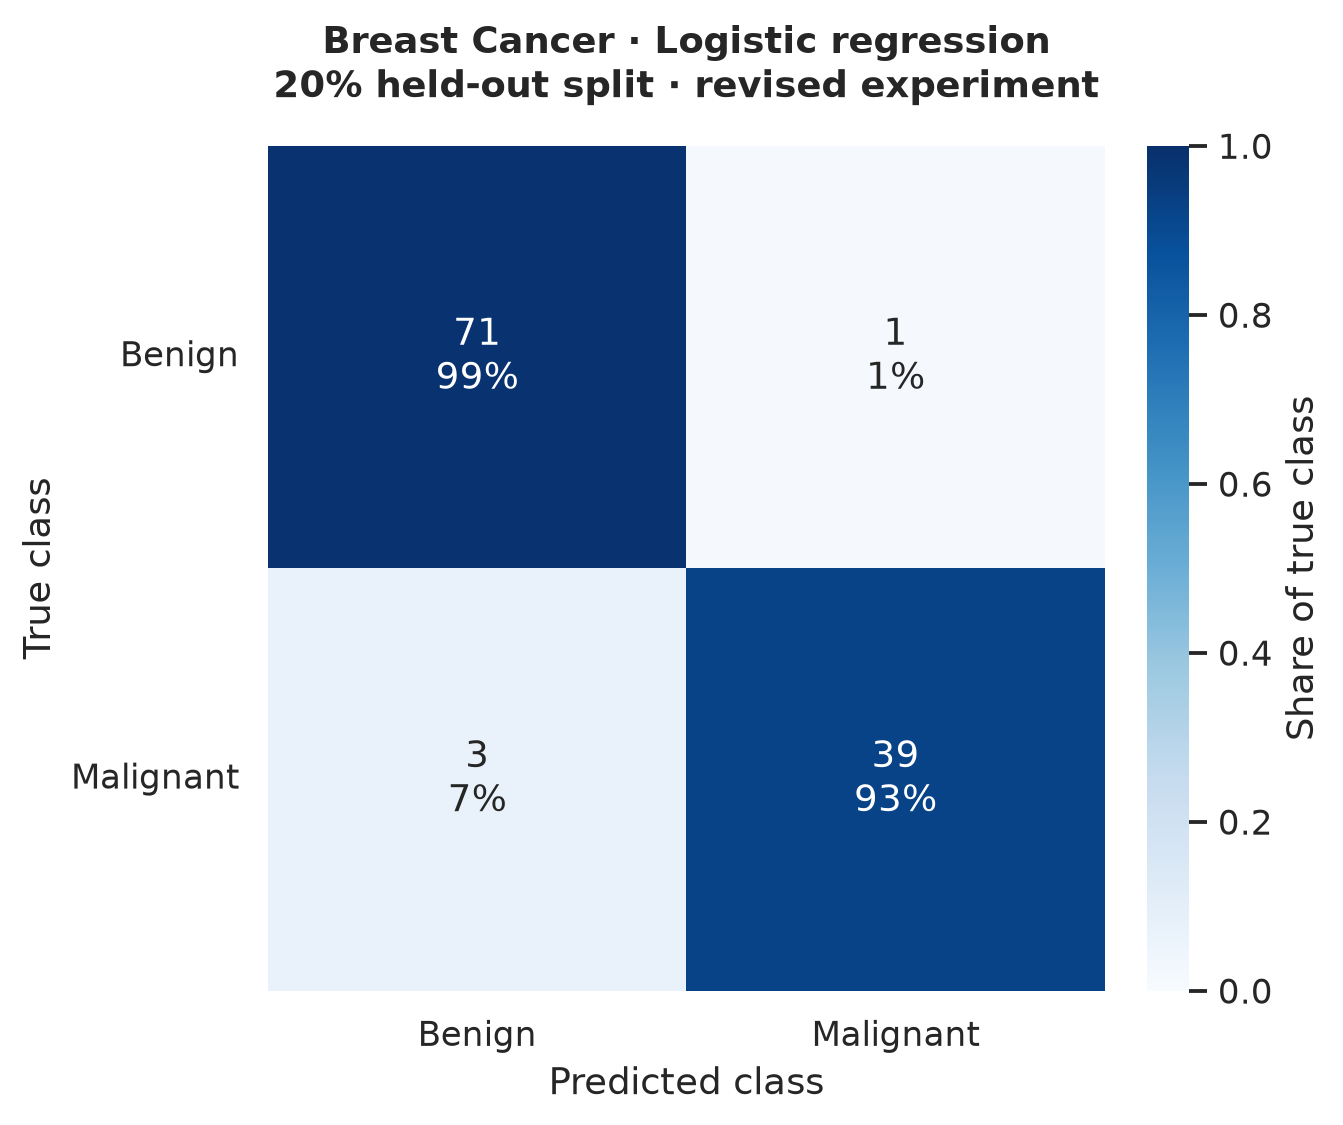

In [7]:
test = pd.read_csv(REPORTS / "test_summary.csv")
display(test.round(4))
for name in scenarios:
    figure(f"{name}_confusion")

Each confusion-matrix cell contains a count and the percentage of its true class. Row-normalized values make minority-class errors easier to see. Cancer metrics treat malignant as the positive class, with the classifier's default decision rule.

,precision,recall,f1-score,support
Benign,0.959459,0.986111,0.972603,72.0
Malignant,0.975000,0.928571,0.951220,42.0


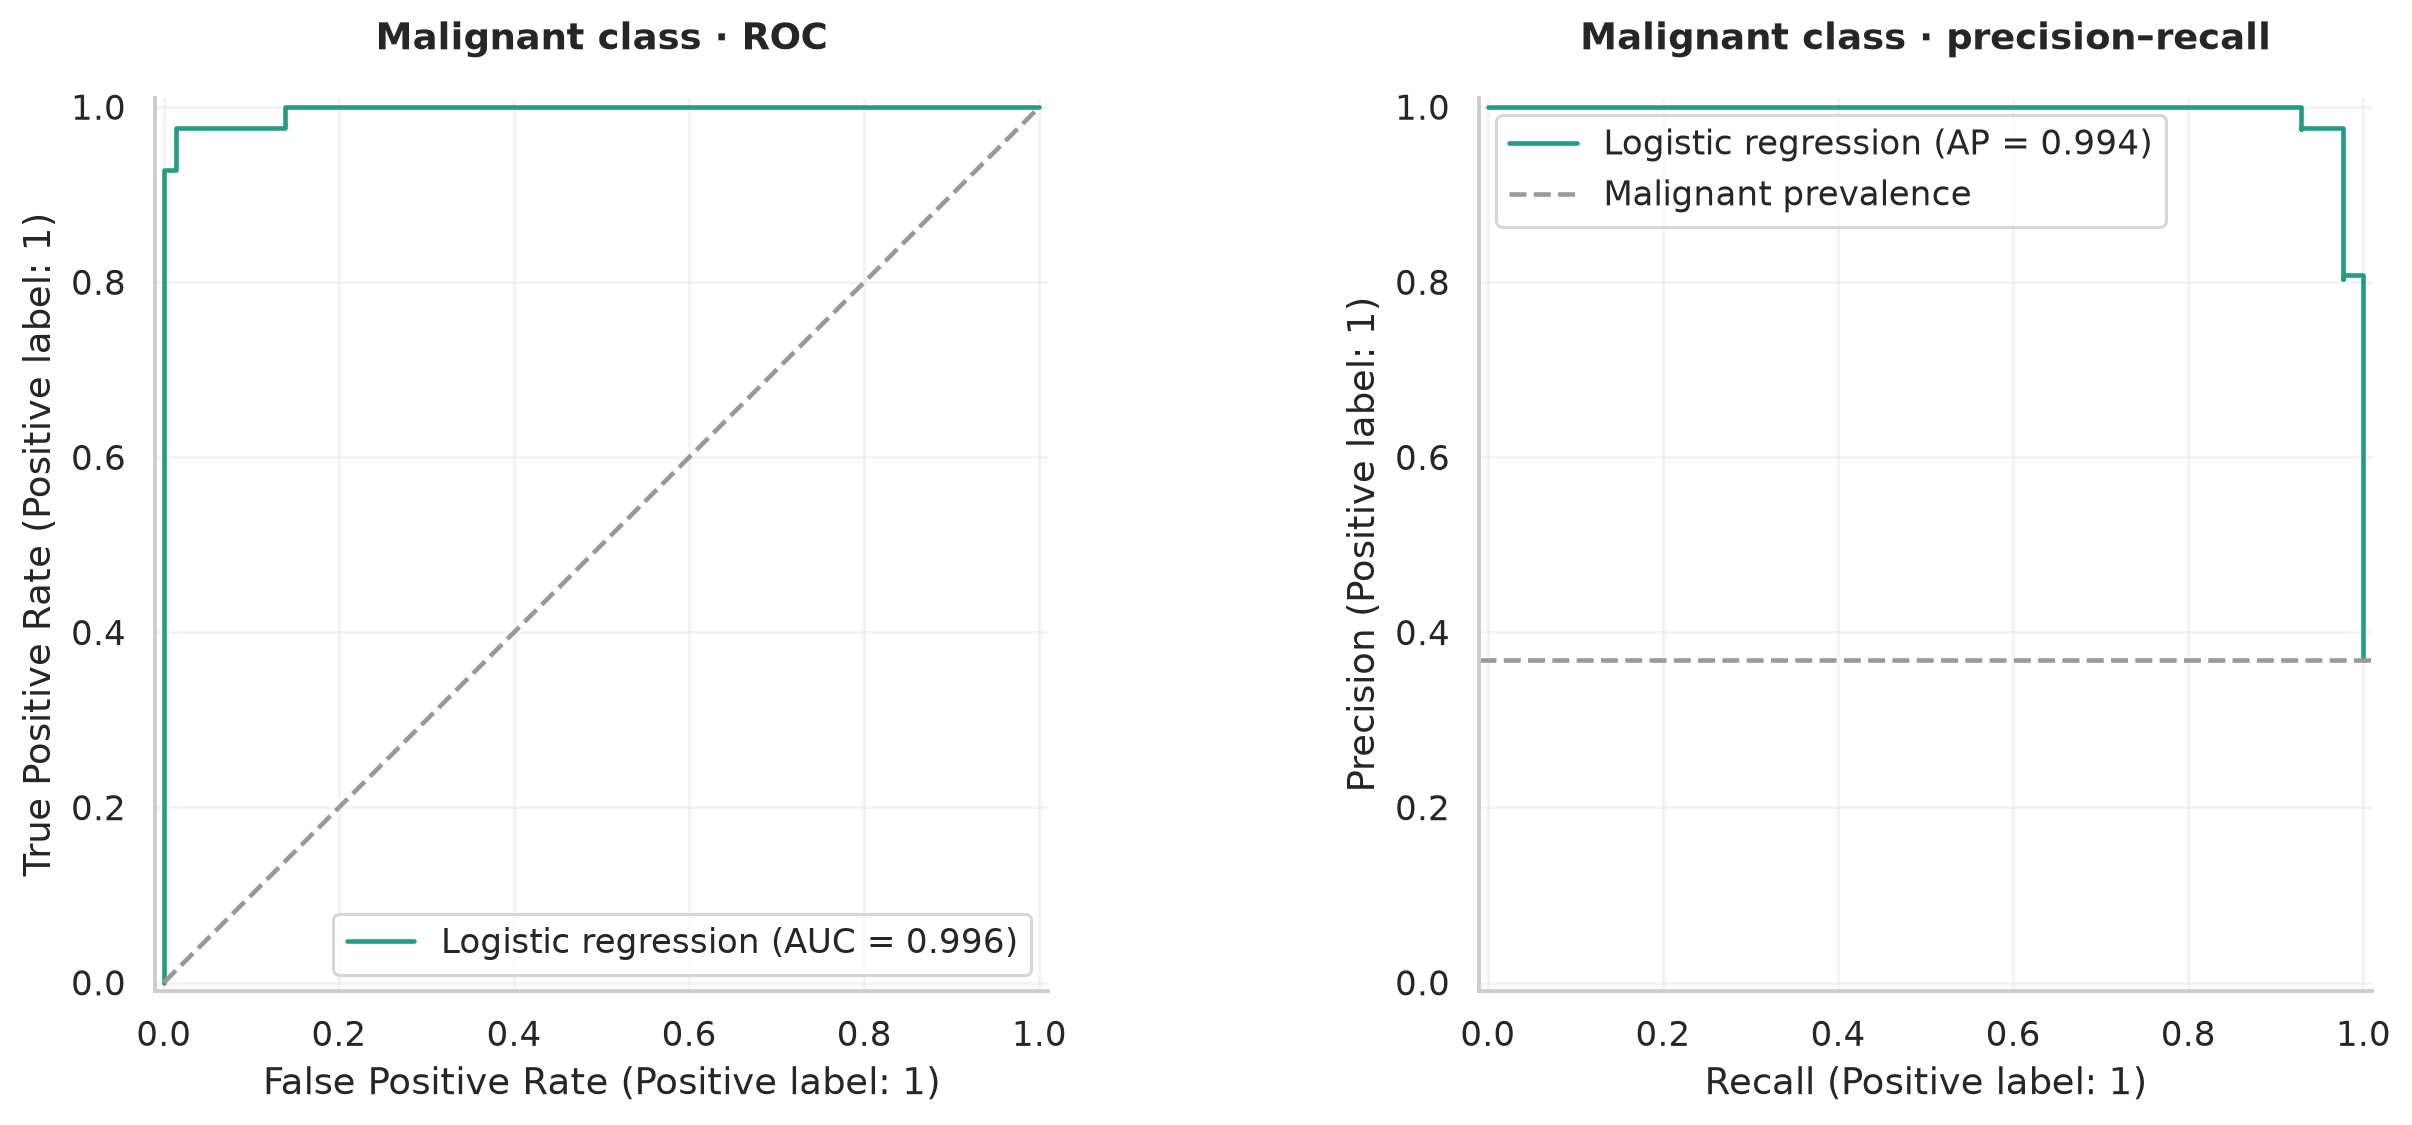

In [8]:
cancer = json.loads((REPORTS / "breast_cancer_classification.json").read_text())
display(pd.DataFrame({name: cancer[name] for name in ["Benign", "Malignant"]}).T)
figure("breast_cancer_curves")

## 6. Inspect what the selected models rely on

Permutation importance shuffles one original feature at a time on the held-out split and measures the drop in macro-F1. Dots show the mean drop in macro-F1 in percentage points; whiskers show standard deviation across 15 shuffles. The right column lists the exact mean and SD. Near-zero or negative values can reflect sampling noise or redundant inputs. Correlated measurements can share importance, so these plots should not be interpreted as causal explanations.

This is a post-evaluation interpretation step. It is not used to choose a model or drop features based on the test set.

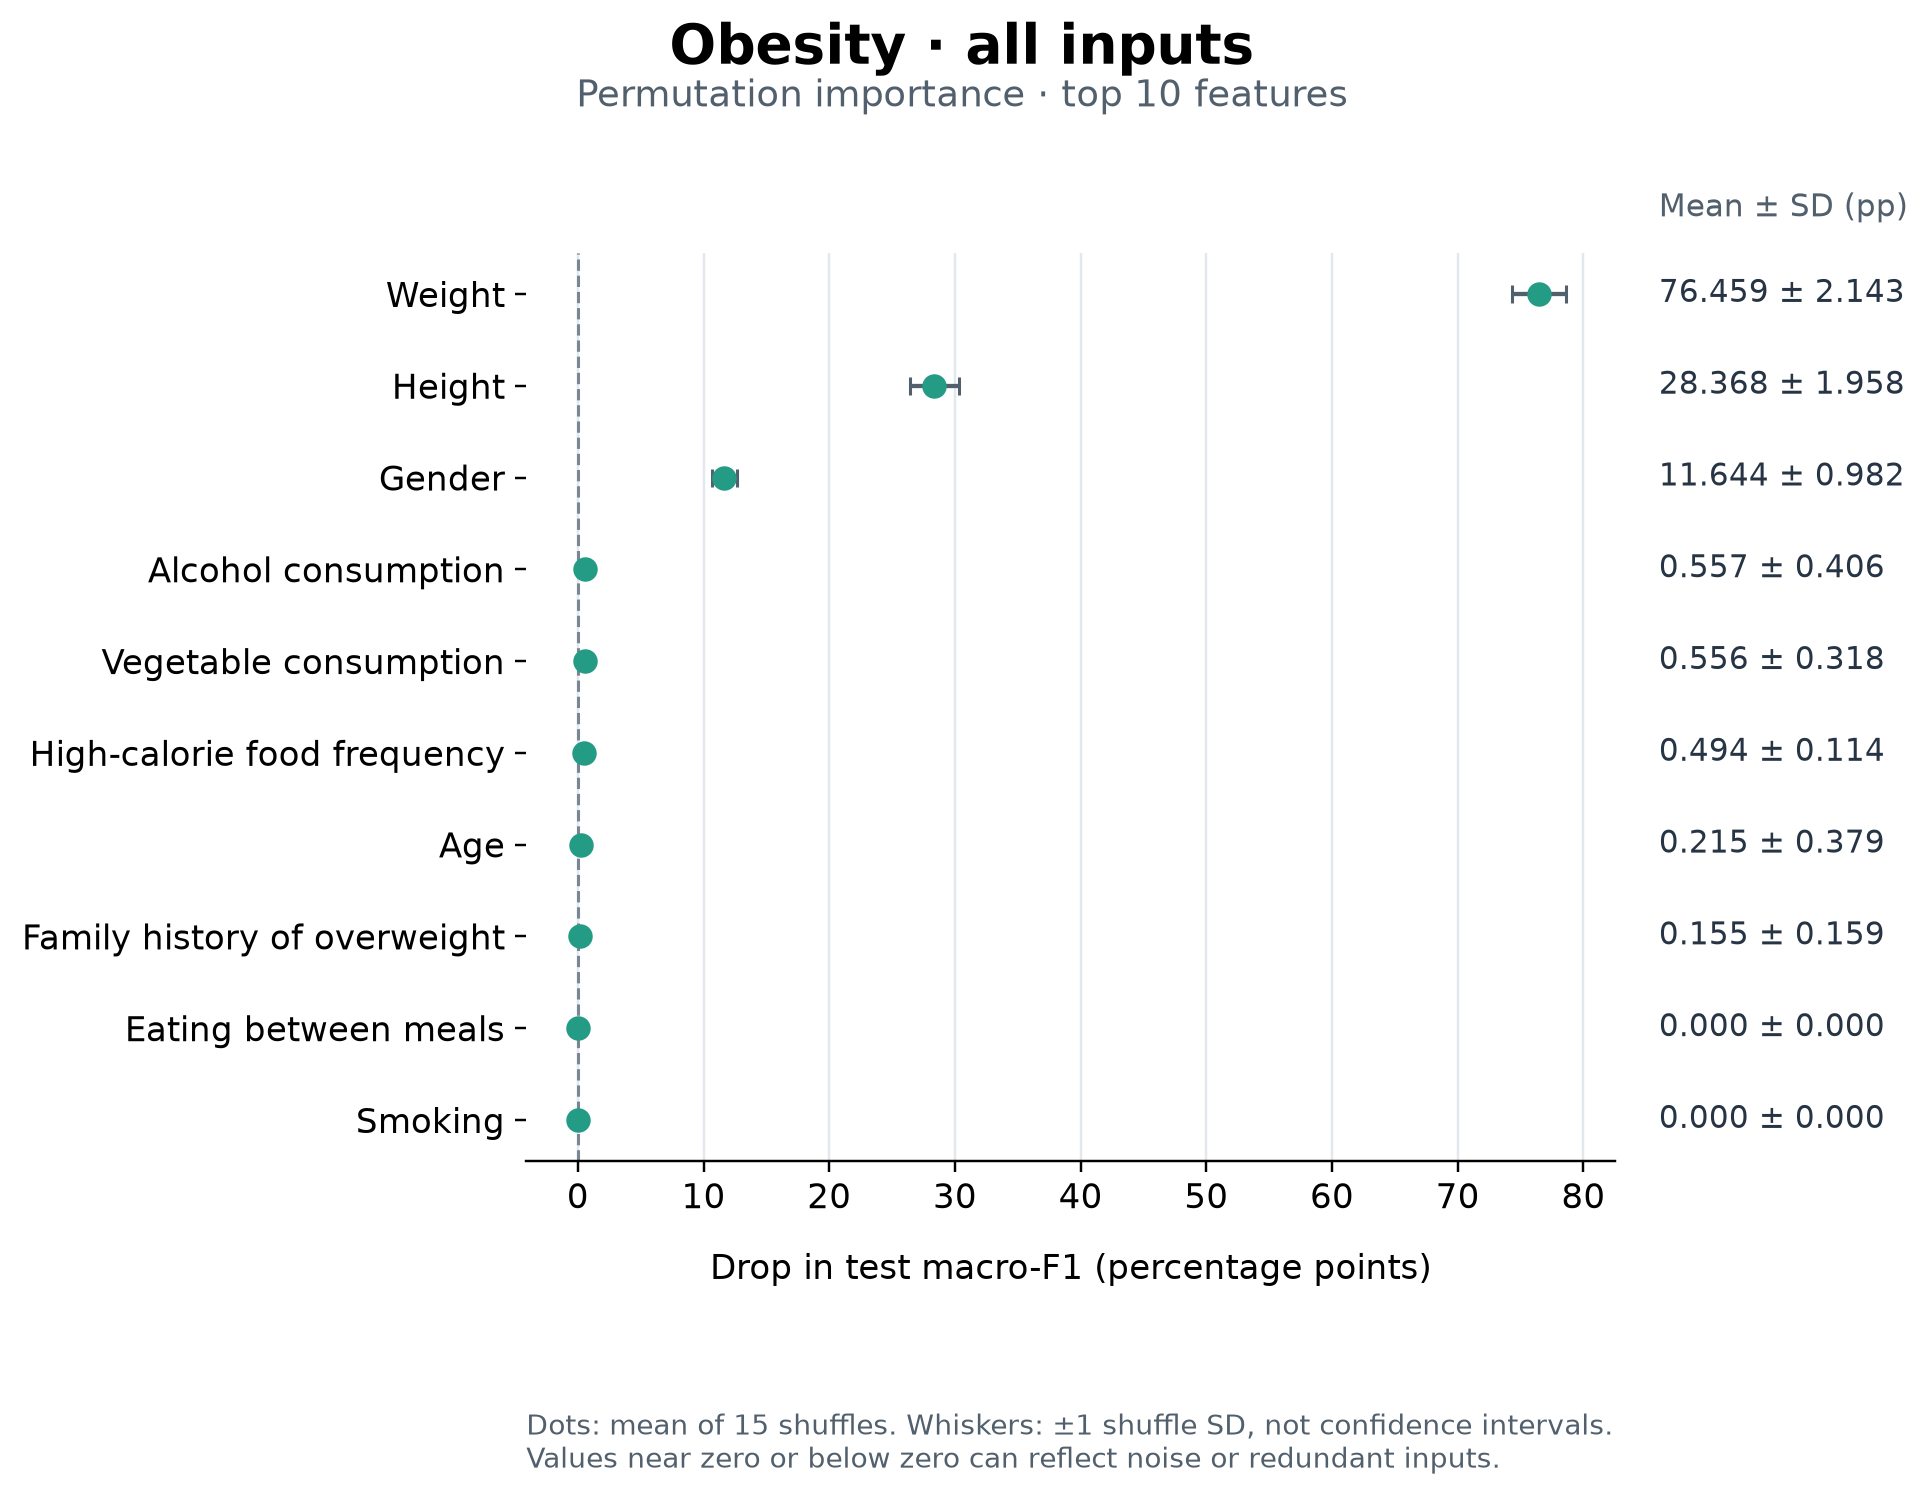

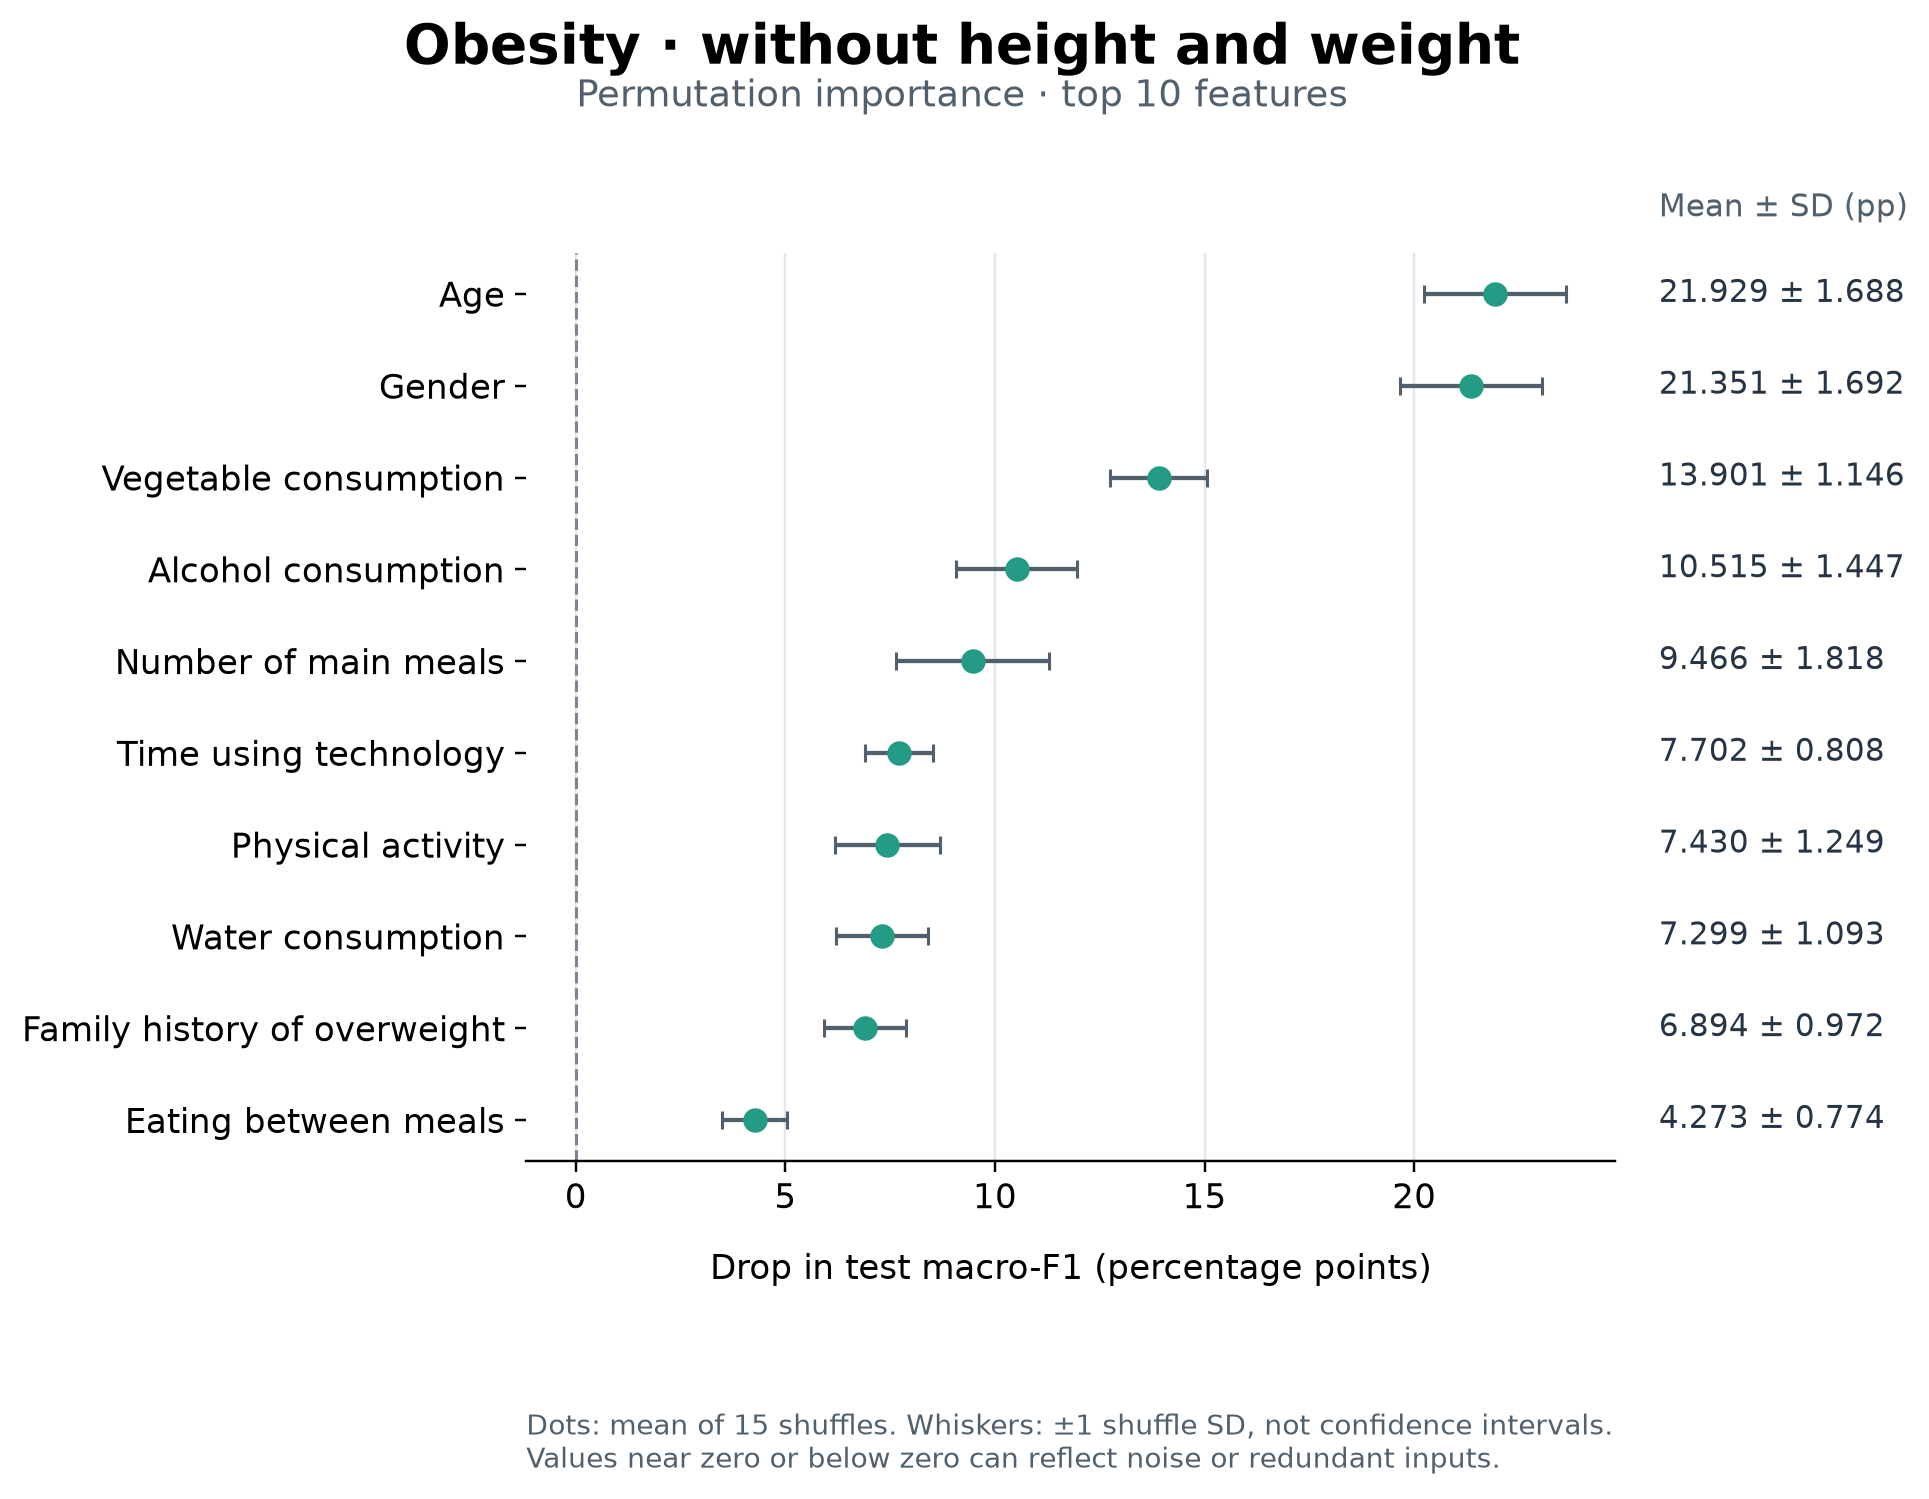

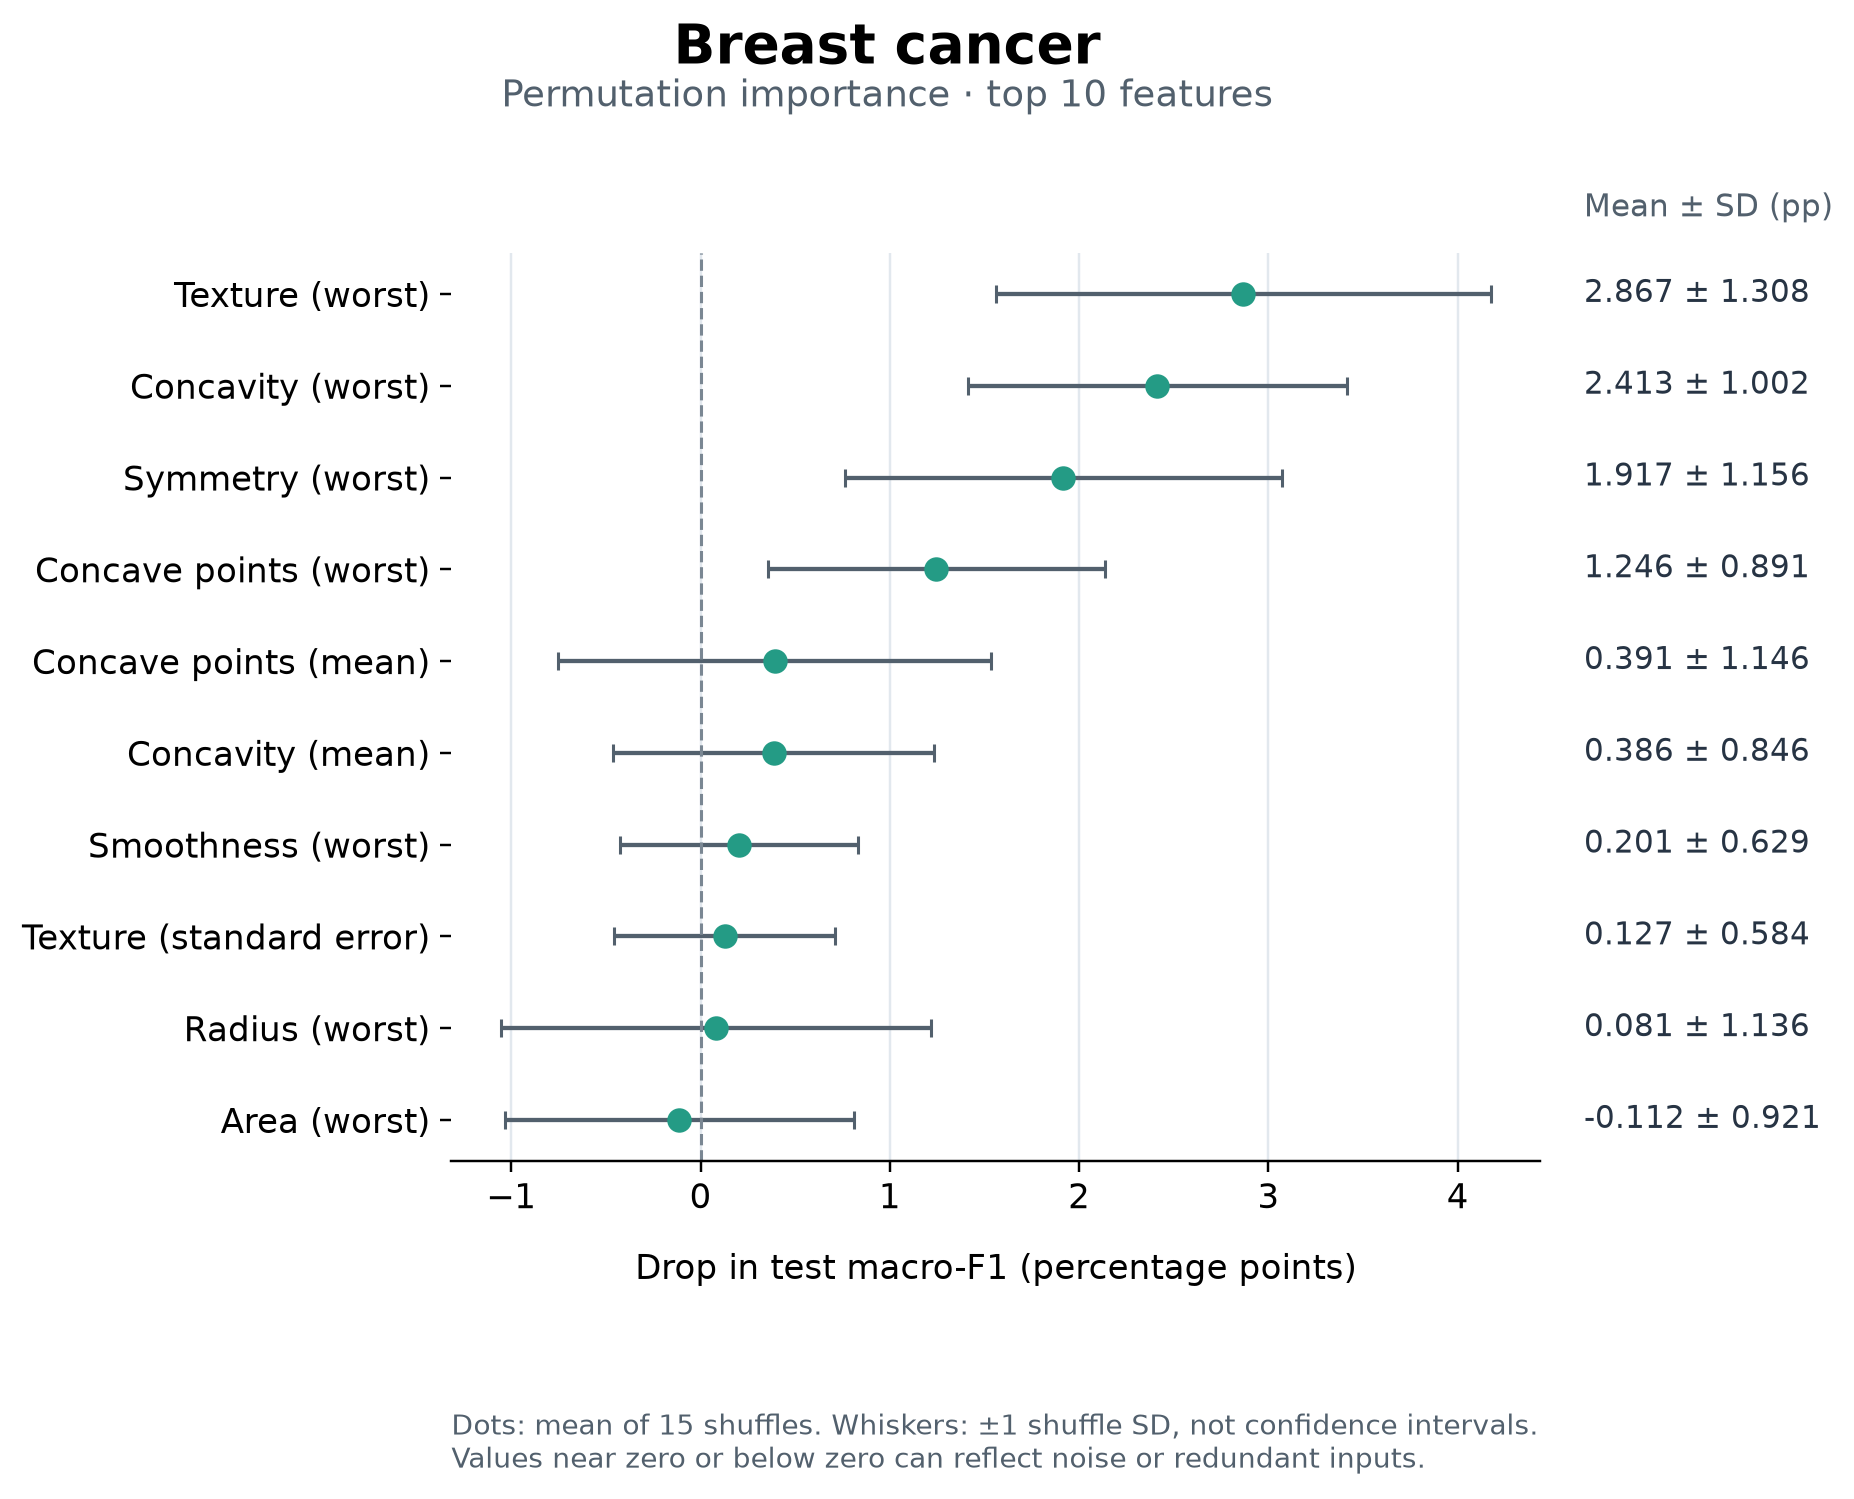

In [9]:
from benchmark import plot_importance

for name in scenarios:
    importance = pd.read_csv(REPORTS / f"{name}_importance.csv")
    plot_importance(importance, name)
    figure(f"{name}_importance")

## 7. Compare runtime and depth sensitivity

Runtime measures fitting only, including preprocessing, with four threads for the boosting models. It excludes prediction and interpretation. Timings depend on the machine, installed library versions and background load.

The LightGBM depth experiment is descriptive. Depth 3, 6 and 9 are compared on development folds; it does not reselect the reported winner or tune against the test results. Other settings, including `num_leaves`, remain at their defaults, so increasing maximum depth need not create a deeper tree.

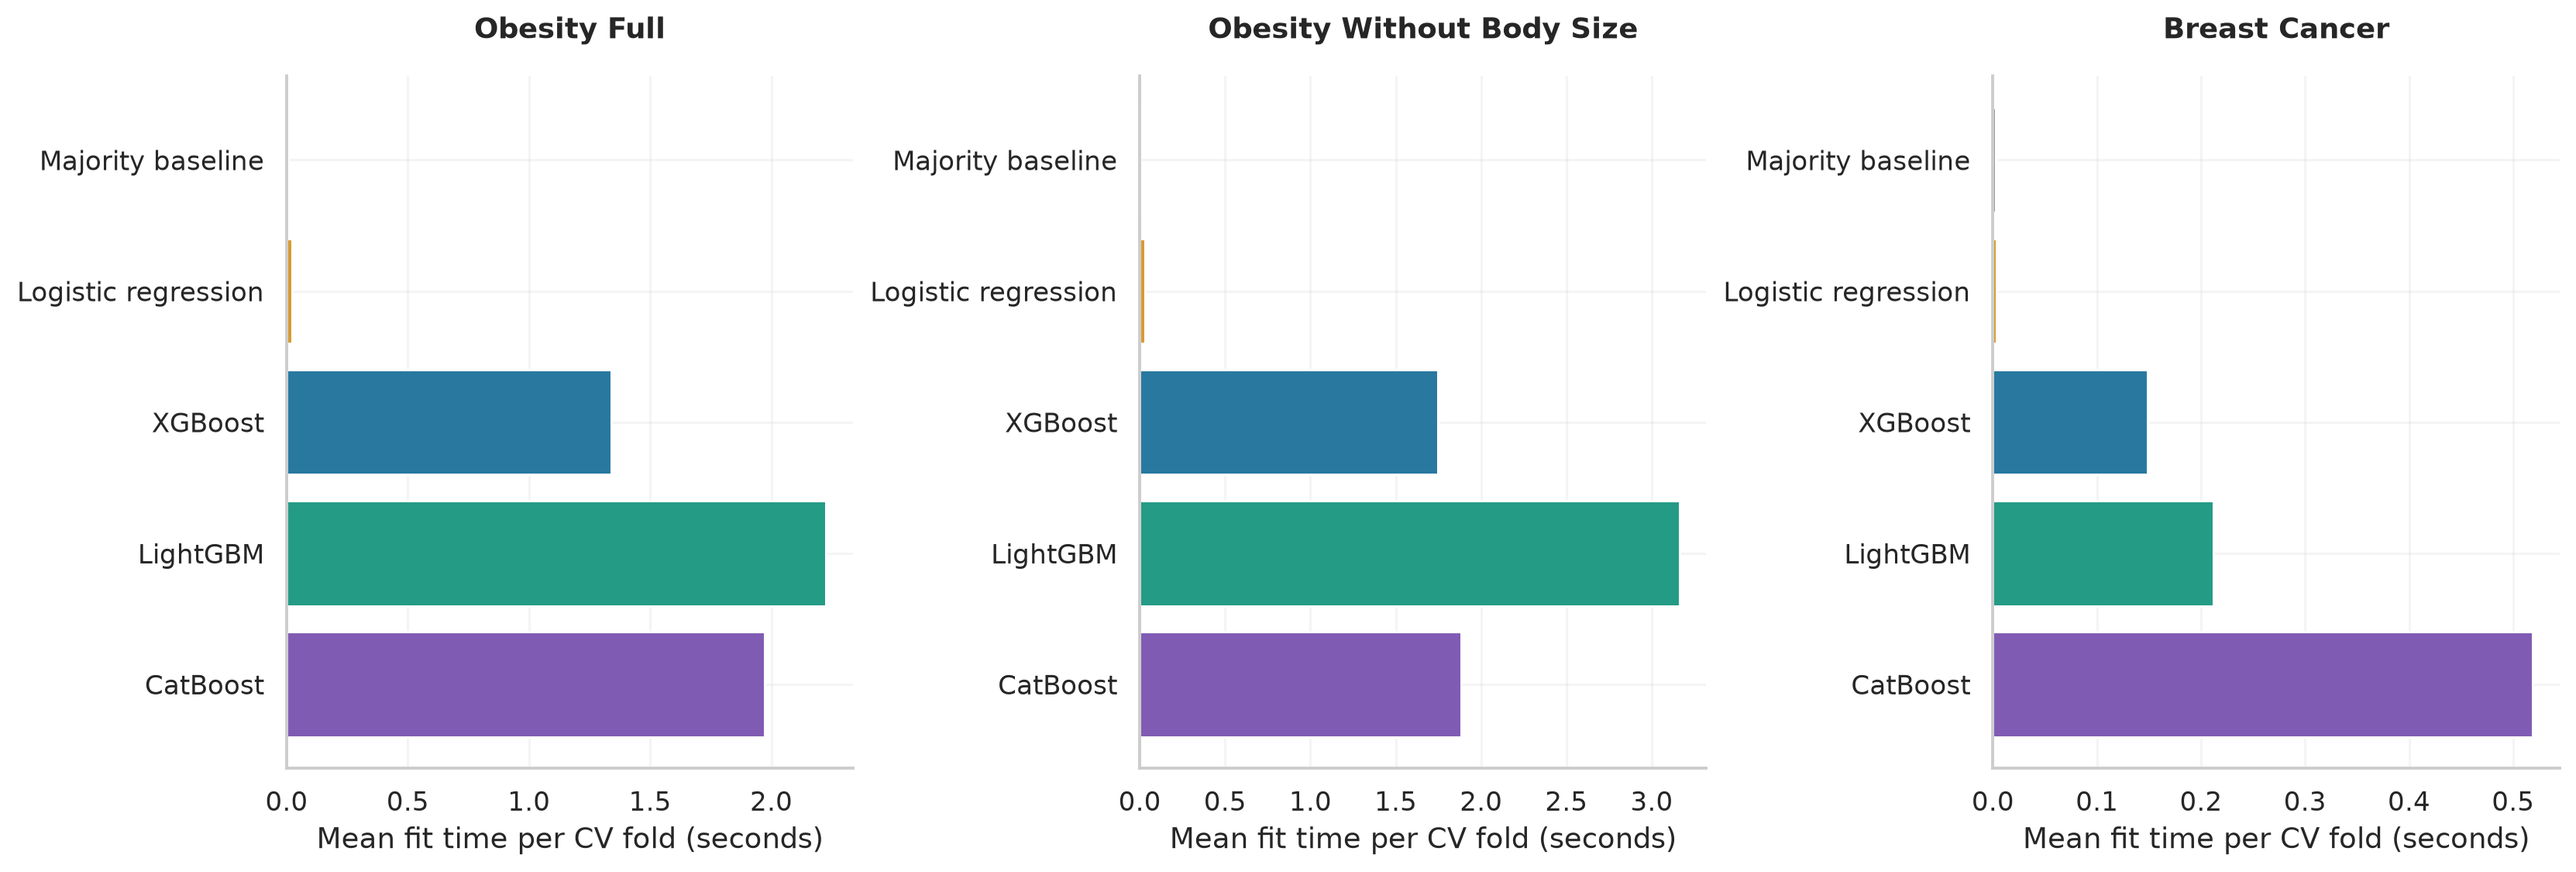

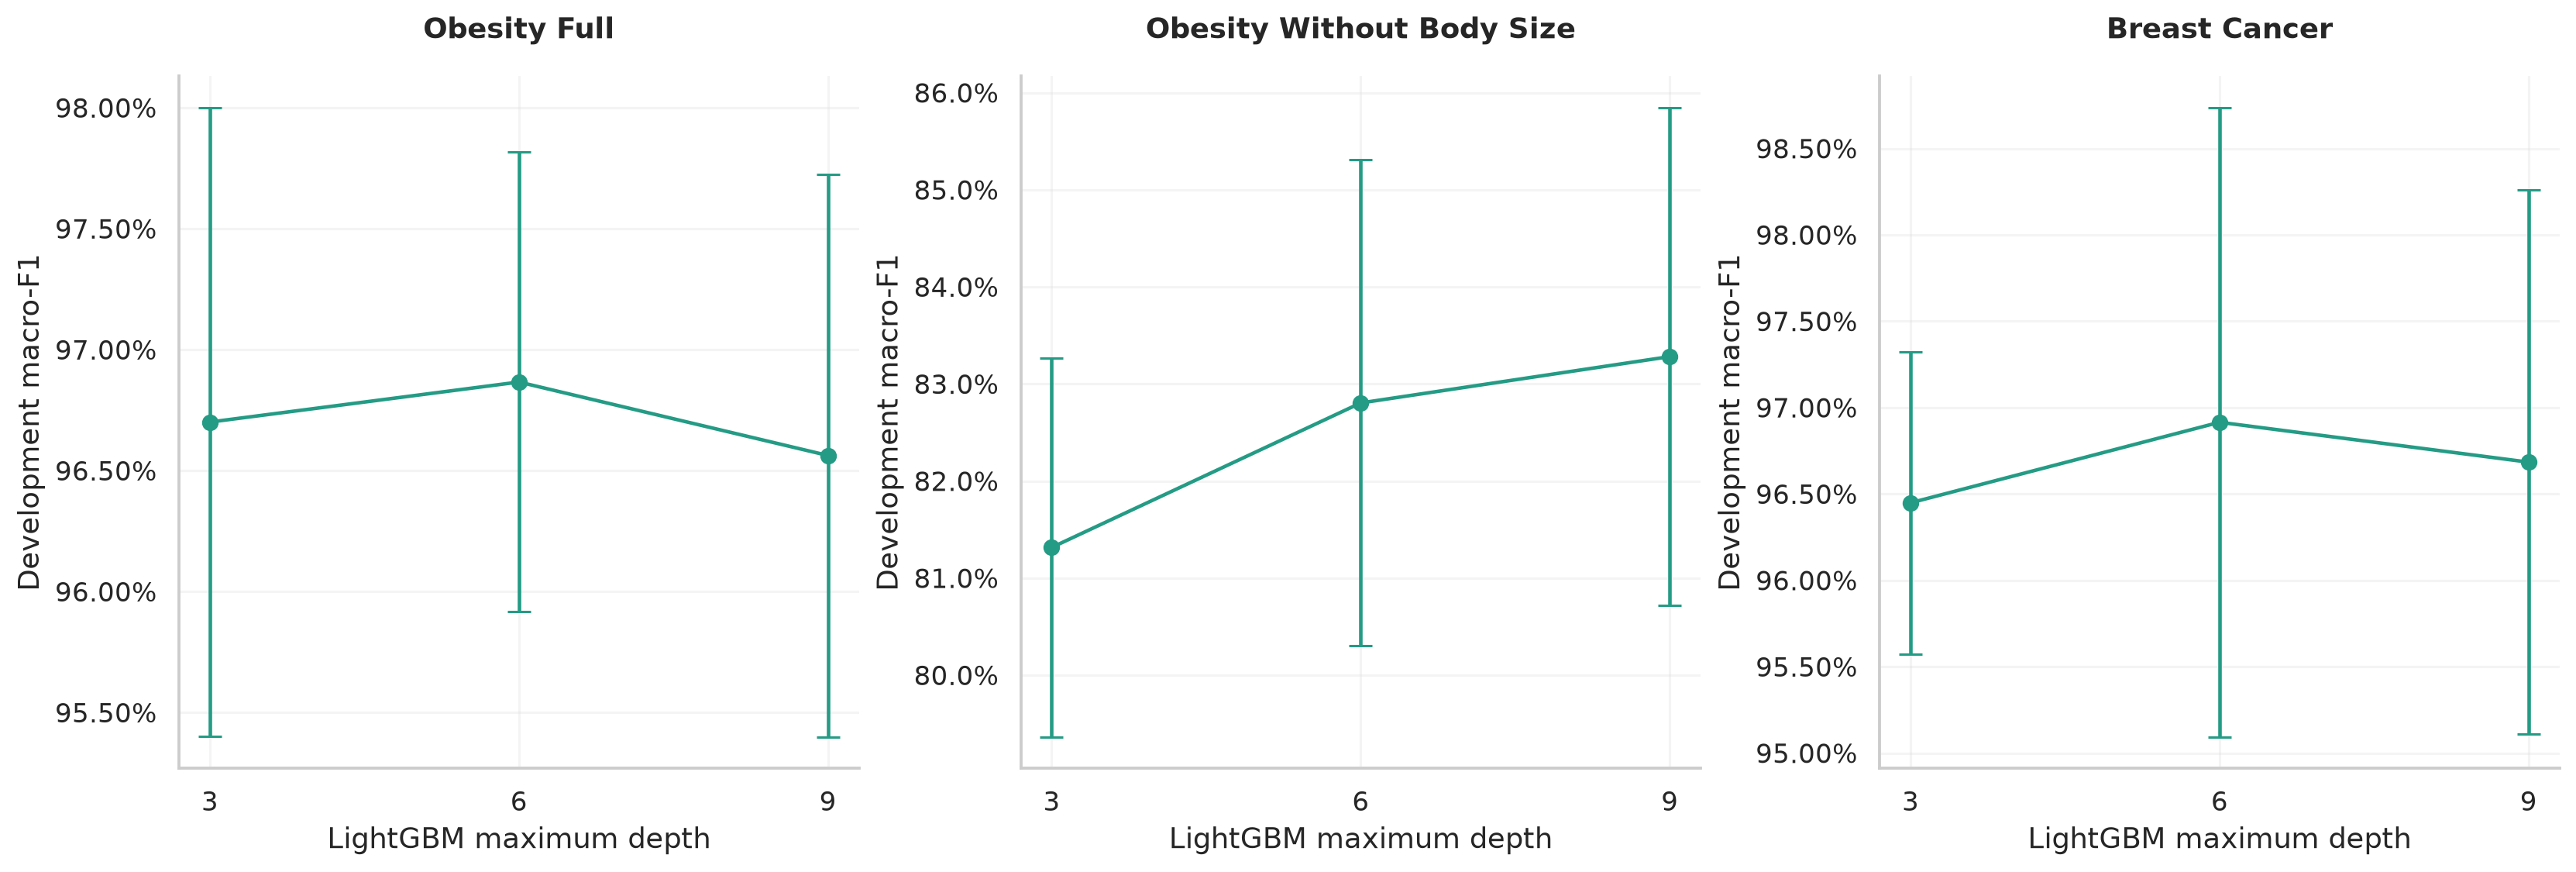

In [10]:
figure("training_time")
figure("depth_sensitivity")

## 8. What I would take from this experiment

The figures make two questions visible: whether boosting improves on a simple model, and whether a strong score survives a change in available inputs. The full interpretation is in `reports/FINDINGS.md`.

The main limits are the obesity dataset's synthetic composition, the small cancer test set, a single split seed, shared rather than individually optimized hyperparameters, and no external validation. This is an educational benchmark, not a clinical tool.

A useful next step would be to repeat the development comparison across several seeds. A more extensive tuning study should use nested cross-validation. Those experiments have not been run in this version.